---
## 5. Limitations: where Monte Carlo struggles
*Lead: Robin Levasseur*

Parts 1 to 4 showed that Monte Carlo gives delivery dates with honest error bars when durations are well behaved.
This part looks for the cases where that promise fails. Real overruns have a heavy tail (5.1), which slows
convergence (5.2) and breaks the CLT error bar (5.3); rare delays need importance sampling (5.4); and no number of
simulations can fix a wrong model (5.5).

In [1]:
# Setup: imports, plotting style and random seed
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "mcpert").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # makes the mcpert package importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

import mcpert as mc
from mcpert.examples import dinner, software_release
from mcpert.style import BLUE, ORANGE, AQUA, INK, MUTED, use_style

use_style()
SEED = 2026  # every number in this notebook is reproducible

In [2]:
# Data used in this part
project, pert_model = software_release()                  # the 7-task running example (Part 3)
ratios = mc.load_sip()["ratio"].to_numpy()                # SiP ratios actual / estimate (Part 1)
sip_model = mc.EmpiricalRatio(project.durations, ratios)  # duration = planned x a real SiP ratio
plan = project.planned_duration()

### 5.1 How heavy is the tail of real overruns?

A ratio $R$ has a **heavy tail of index $\alpha > 0$** if $P(R > x) \approx C x^{-\alpha}$ for large $x$. Then
$$
\mathbb E[R^p] = \int_0^\infty p\, x^{p-1} P(R > x)\, dx < \infty \iff p < \alpha ,
$$
because the integrand behaves like $x^{p - 1 - \alpha}$ at infinity. The mean is finite only if $\alpha > 1$ and the
variance only if $\alpha > 2$: **when $\alpha \le 2$, the CLT of Proposition 3 does not apply.**

To estimate $\alpha$, sort the sample as $X_{(1)} \ge X_{(2)} \ge \dots$ and keep the $k$ largest values (Hill, 1975):
$$
\frac{1}{\hat\alpha_k} = \frac1k \sum_{i=1}^{k} \ln \frac{X_{(i)}}{X_{(k+1)}} .
$$
For a Pareto law, $P(X > x) = (x_{\min}/x)^{\alpha}$, so $P\big(\ln(X/x_{\min}) > y\big) = e^{-\alpha y}$: the log-excess is
exponential with rate $\alpha$, hence of mean $1/\alpha$. Above the threshold $X_{(k+1)}$, the $k$ largest values are again
Pareto with the same $\alpha$, so the average of their log-excesses estimates $1/\alpha$. Small $k$ gives a noisy estimate,
large $k$ uses values that are no longer in the tail.

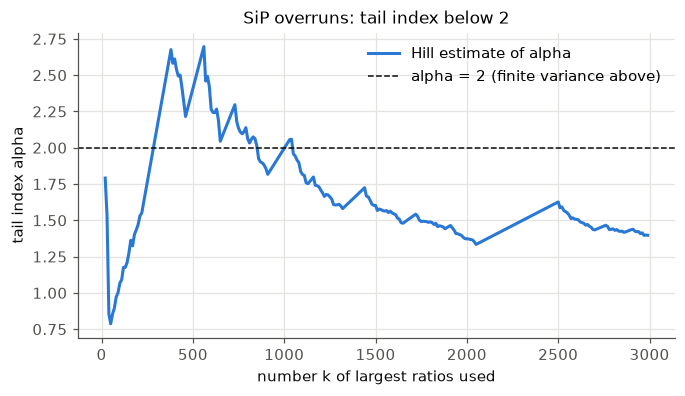

Hill estimate for k in [1000, 3000]: 1.33 to 2.06


In [3]:
# Hill plot of the SiP ratios
ks = np.arange(20, 3000, 10)
alpha_hat = np.array([mc.hill_tail_index(ratios, k) for k in ks])

fig, ax = plt.subplots()
ax.plot(ks, alpha_hat, color=BLUE, label="Hill estimate of alpha")
ax.axhline(2, color=INK, lw=1, ls="--", label="alpha = 2 (finite variance above)")
ax.set(xlabel="number k of largest ratios used", ylabel="tail index alpha",
       title="SiP overruns: tail index below 2")
ax.legend()
plt.show()

stable = (ks >= 1000) & (ks <= 3000)
print(f"Hill estimate for k in [1000, 3000]: {alpha_hat[stable].min():.2f} to {alpha_hat[stable].max():.2f}")

**The SiP overruns have a tail index below 2.** For $k$ between 1,000 and 3,000 the Hill estimate stays between 1.33
and 1.7, apart from a short excursion up to 2.06 for $k \approx 1{,}000$ to $1{,}040$. The straight segments are blocks of
tied ratios (SiP hours are rounded): inside a block $X_{(k+1)}$ is constant and $\hat\alpha_k$ grows linearly in $k$.

**A finite sample cannot prove an infinite variance.** The empirical variance of 12,299 ratios is always finite, and a
law cut off at the largest observed ratio (281) fits the data just as well. What the Hill plot says is that, over the
observed range, the tail decays like $x^{-1.5}$: the variance is dominated by a handful of tasks and keeps growing as
more data arrive. Flyvbjerg et al. (2022) find the same power-law tail in the cost overruns of 5,392 IT projects.

### 5.2 Slow and erratic convergence

For each of three models of the running example (Beta-PERT, SiP ratios, Pareto ratios with $\alpha = 1.5$ and
$\mathbb E[R] = 1$), we run 5 independent studies of $n = 100{,}000$ simulations and plot the running estimate of $\mathbb E[T]$.

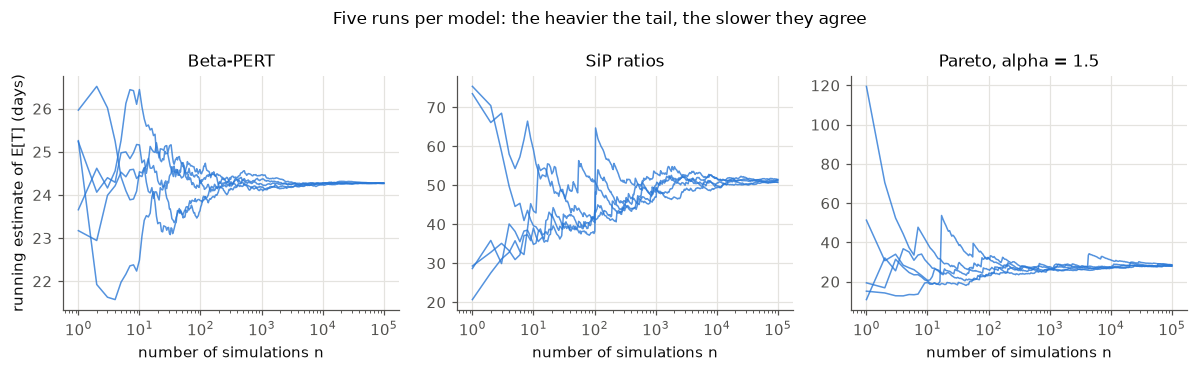

In [4]:
# Running estimate of E[T] for three delay models
n, runs = 100_000, 5
models = {
    "Beta-PERT": pert_model,
    "SiP ratios": sip_model,
    "Pareto, alpha = 1.5": mc.ParetoRatio(project.durations, alpha=1.5),
}
rng = np.random.default_rng(SEED)
points = np.unique(np.geomspace(1, n, 400).astype(int))  # ~400 log-spaced sample sizes

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, model) in zip(axes, models.items()):
    for run in range(runs):
        T = mc.simulate(project, model, n, rng=rng)
        ax.plot(points, mc.running_mean(T)[points - 1], color=BLUE, lw=1, alpha=0.8)
    ax.set_xscale("log")
    ax.set(title=name, xlabel="number of simulations n")
axes[0].set_ylabel("running estimate of E[T] (days)")
fig.suptitle("Five runs per model: the heavier the tail, the slower they agree", fontsize=11)
fig.tight_layout()
plt.show()

**The heavier the tail, the longer the runs disagree.** With Beta-PERT the five runs agree within a fraction of a day
after about 1,000 simulations. With SiP and Pareto ratios they still differ by several days at $n = 1{,}000$, and each
curve jumps whenever a huge ratio is drawn.

**With $\alpha = 1.5$, ten times more precision costs a thousand times more simulations.** When $1 < \alpha < 2$, the
generalised CLT replaces $n^{-1/2}$ by $n^{1/\alpha - 1}$: the error $\hat\mu_n - \mu$ is of order $n^{-1/3}$, with a stable
(non-Gaussian) limit.

### 5.3 Error bars that lie

We repeat the coverage experiment of Section 3.7 for $n = 100$, $1{,}000$ and $10{,}000$, with 400 independent studies
each: how often does the 95% CLT interval $\hat\mu_n \pm 1.96\, \hat\sigma_n / \sqrt n$ contain the true $\mathbb E[T]$?
For Beta-PERT and SiP the truth comes from 1,000,000 simulations. For the Pareto model we use a 4-task chain, whose
$\mathbb E[T] = 5 + 10 + 5 + 1 = 21$ days is known exactly (a sum of means). The order-statistics interval for the
90% date (Proposition 5) is the control.

In [5]:
# Coverage of 95% intervals as n grows
sizes, reps = (100, 1_000, 10_000), 400

# 1. True values. Pareto chain: E[T] = sum of the means = 21 exactly. PERT and SiP: one large run.
chain = mc.Project([5, 10, 5, 1], [[], [0], [1], [2]])
chain_model = mc.ParetoRatio(chain.durations, alpha=1.5)
true_chain = chain_model.mean().sum()
T_pert = mc.simulate(project, pert_model, 1_000_000, rng=SEED)
T_sip = mc.simulate(project, sip_model, 1_000_000, rng=SEED)
true_pert, true_sip, true_sip_q90 = T_pert.mean(), T_sip.mean(), np.quantile(T_sip, 0.9)
print(f"true values: E[T] Beta-PERT = {true_pert:.3f}, E[T] SiP = {true_sip:.3f}, "
      f"90% date SiP = {true_sip_q90:.3f}, E[T] Pareto chain = {true_chain:g}")

# 2. Coverage of each interval, for each n.
cases = {
    "Beta-PERT, CLT for E[T]": (project, pert_model, mc.mean_ci, true_pert),
    "SiP, CLT for E[T]": (project, sip_model, mc.mean_ci, true_sip),
    "Pareto chain, CLT for E[T]": (chain, chain_model, mc.mean_ci, true_chain),
    "SiP, order statistics for 90% date": (project, sip_model, lambda T: mc.quantile_ci(T, 0.9), true_sip_q90),
}
table = pd.DataFrame(index=list(cases), columns=[f"n = {n:,}" for n in sizes], dtype=float)
for name, (proj, model, interval_fn, truth) in cases.items():
    for n in sizes:
        sample_fn = lambda rng, proj=proj, model=model, n=n: mc.simulate(proj, model, n, rng=rng)
        table.loc[name, f"n = {n:,}"] = mc.coverage(sample_fn, interval_fn, truth, reps=reps, rng=SEED)

# 3. One table, target 95%.
display(table.style.format("{:.1%}").set_caption("coverage of 95% intervals (400 repetitions)"))

true values: E[T] Beta-PERT = 24.265, E[T] SiP = 51.191, 90% date SiP = 76.381, E[T] Pareto chain = 21


,n = 100,"n = 1,000","n = 10,000"
"Beta-PERT, CLT for E[T]",94.5%,95.0%,94.8%
"SiP, CLT for E[T]",69.8%,93.0%,95.0%
"Pareto chain, CLT for E[T]",76.5%,78.2%,77.5%
"SiP, order statistics for 90% date",95.8%,96.0%,93.5%


**The CLT interval keeps its promise only when the tail is light.** Beta-PERT covers 94.5% to 95.0% for every $n$.
With SiP ratios the coverage is 69.8% at $n = 100$ and reaches 95.0% only at $n = 10{,}000$. With Pareto ratios it
stays between 76.5% and 78.2% whatever $n$: more simulations do not help.

The interval plugs $\hat\sigma_n$ in place of $\sigma$. With a heavy tail, $\hat\sigma_n$ is driven by a few extreme values:
in most studies the huge delays have not been drawn yet, so $\hat\mu_n$ and $\hat\sigma_n$ are both too small and the
interval is too short and too low. When $\alpha < 2$, $\sigma = \infty$ and this never improves. The SiP bootstrap has a
finite variance only because its ratios are capped at 281, so its CLT kicks in, but late.

**The distribution-free interval keeps its promise.** The order-statistics interval for the 90% date covers 93.5% to
96.0% of the time, within the $\pm 2.2$ points of noise of 400 repetitions, as Proposition 5 guarantees without any
moment assumption. With heavy tails we should report quantiles with order-statistics intervals and probabilities
with Hoeffding intervals, and distrust a CLT error bar on $\mathbb E[T]$.

### 5.4 Rare events: importance sampling

For a small probability $p = P(T > t)$, the plain estimator $\hat p_n$ has standard deviation $\sqrt{p(1-p)/n}$, so its
**relative error** is
$$
\frac{\sqrt{p(1-p)/n}}{p} = \sqrt{\frac{1-p}{np}} \approx \frac{1}{\sqrt{np}} .
$$
It depends on the expected number $np$ of rare events observed. For $p \approx 10^{-3}$ and $n = 10^5$ we see about 100
of them, hence about 10% (20% at 95%); 1% at 95% would need $n \approx 4 \times 10^{7}$.

**Importance sampling** draws the scenario from a proposal $g$ that makes delays more frequent and corrects with the
weight $w = f/g$, where $f$ is the true law. Here a scenario is the vector $J = (J_1, \dots, J_k)$ of the SiP ratios given
to the $k$ tasks, with $f(J) = m^{-k}$. If $g(J) > 0$ for every $J$,
$$
\mathbb E_g\Big[\mathbf 1\{T(J) > t\}\, \frac{f(J)}{g(J)}\Big] = \sum_J g(J)\, \mathbf 1\{T(J) > t\}\, \frac{f(J)}{g(J)}
= \sum_J f(J)\, \mathbf 1\{T(J) > t\} = p ,
$$
so the estimator $\frac1n \sum_s \mathbf 1\{T^{(s)} > t\}\, w^{(s)}$ is **unbiased for every proposal**. Its variance, however,
depends strongly on $g$.

We tilt each ratio towards long tasks: $r_j$ is drawn with probability $q_j = r_j^\theta / \sum_l r_l^\theta$ instead of $1/m$
($\theta = 0$ is plain Monte Carlo).
* **Tilt all tasks:** every $J_i \sim q$, so $g(J) = \prod_i q_{J_i}$ and $w = \prod_{i=1}^{k} \dfrac{1}{m\, q_{J_i}}$.
* **Tilt one task:** a task $I$ chosen uniformly is drawn from $q$, the others uniformly. Averaging over $I$,
  $g(J) = \frac1k \sum_i q_{J_i}\, m^{-(k-1)}$, so $w = \Big(\frac1k \sum_{i=1}^{k} m\, q_{J_i}\Big)^{-1}$.

The second proposal follows the **one big jump** principle: for i.i.d. heavy-tailed (subexponential) $R_i$,
$P(R_1 + \dots + R_k > x) \sim P(\max_i R_i > x) \sim k\, P(R_1 > x)$ as $x \to \infty$. A huge total delay is typically caused
by one huge task, not by every task being a bit late.

In [6]:
# P(T > 80 x plan): plain Monte Carlo versus importance sampling, same budget
t = 80 * plan
n = 100_000

# 1. Reference: 4,000,000 plain simulations, in 4 batches of 1,000,000 to limit memory.
rng = np.random.default_rng(SEED)
late = np.concatenate([mc.simulate(project, sip_model, 1_000_000, rng=rng) > t for _ in range(4)])
reference = mc.prob_ci(late, method="clt")
print(f"reference P(T > {t:g} days) = {reference.value:.3e}  "
      f"(relative error 95%: {reference.radius / reference.value:.1%}, n = {reference.n:,})")

# 2. Same budget n = 100,000 for each tilt and each theta (theta = 0 is plain Monte Carlo).
rows = {}
for tilt in ["all", "one"]:
    for theta in [0, 0.5, 1, 1.5, 2, 3]:
        est = mc.tail_probability_is(project, project.durations, ratios, t, theta, n=n,
                                     rng=SEED, tilt=tilt)
        rows[(tilt, theta)] = {"estimate": est.value, "relative error (95%)": est.radius / est.value,
                               "radius": est.radius}
results = pd.DataFrame(rows).T.rename_axis(["tilt", "theta"])
display(results[["estimate", "relative error (95%)"]].unstack("tilt").style
        .format("{:.3e}", subset=["estimate"]).format("{:.1%}", subset=["relative error (95%)"])
        .format_index("{:g}", axis=0))

# 3. Variance reduction of tilt "one" against plain Monte Carlo, same n: (radius ratio)^2.
plain_radius = results.loc[("one", 0), "radius"]
for theta in [1, 2, 3]:
    print(f"tilt 'one', theta = {theta}: variance divided by "
          f"{(plain_radius / results.loc[('one', theta), 'radius']) ** 2:.0f}")

reference P(T > 1680 days) = 8.718e-04  (relative error 95%: 3.3%, n = 4,000,000)


tilt 'one', theta = 1: variance divided by 20
tilt 'one', theta = 2: variance divided by 275
tilt 'one', theta = 3: variance divided by 483


**Tilting one task works; tilting all tasks fails.** The reference from 4,000,000 plain simulations is
$p \approx 8.7 \times 10^{-4}$ (relative error 3.3%). With the same budget $n = 100{,}000$, plain Monte Carlo has a
relative error of 21%, while "tilt one" gives $9.1 \times 10^{-4}$ with 1.2% at $\theta = 2$ and 0.9% at $\theta = 3$. The
variance is divided by about 275 at $\theta = 2$ (483 at $\theta = 3$): 100,000 tilted simulations are worth tens of
millions of plain ones. The tilted estimates sit about two reference standard errors above $8.7 \times 10^{-4}$, and they
are the more precise of the two.

**"Tilt all" gives estimates that are wrong by orders of magnitude for $\theta \ge 1.5$.** At $\theta = 2$ and $3$ it
returns $1.8 \times 10^{-7}$ and $5.1 \times 10^{-10}$, and the CLT interval at $\theta = 2$ excludes the true value. Its weight is a
product of $k = 7$ factors: making every task long creates scenarios the true law almost never produces, so most
weights are tiny and the mean is driven by rare huge weights that a finite sample misses.

**The one-big-jump principle explains the difference.** Under the true law, $T > 80 \times$ plan happens because one
task takes a huge ratio, which is exactly what "tilt one" simulates. Its weight satisfies $w \le k / (m\, q_{J_I})$, which
is small whenever the tilted task is long, so the weights stay bounded on the rare event.

### 5.5 Model risk: Monte Carlo cannot fix a wrong model

So far the tasks were independent. We compare with the opposite extreme, one common ratio $R$ for all tasks (same
team, same estimator, same optimism), keeping the same SiP law for each task.

In [7]:
# Independent tasks versus one common ratio for all tasks
n, k = 100_000, project.k
rng = np.random.default_rng(SEED)

# 1. Same marginal law for each task; only the dependence between tasks changes.
U_independent = rng.random((n, k))
U_common = np.repeat(rng.random((n, 1)), k, axis=1)  # one ratio quantile for all tasks

# 2. E[T], 90% date and P(on time at plan), each with its 95% interval.
rows = {}
for name, U in [("independent tasks", U_independent), ("one common ratio", U_common)]:
    T = project.completion_time(sip_model.ppf(U))
    mean, q90, on_time = mc.mean_ci(T), mc.quantile_ci(T, 0.9), mc.prob_ci(T <= plan)
    rows[name] = {"E[T] (days)": mean.value, "E[T] 95% CI": mean.interval,
                  "90% date (days)": q90.value, "90% date 95% CI": q90.interval,
                  "P(on time at plan)": on_time.value, "P(on time) 95% CI": on_time.interval}
display(pd.DataFrame(rows).T.style.format("{:.2f}", subset=["E[T] (days)", "90% date (days)"])
        .format("{:.3f}", subset=["P(on time at plan)"]))

,E[T] (days),E[T] 95% CI,90% date (days),90% date 95% CI,P(on time at plan),P(on time) 95% CI
independent tasks,51.39,"[50.72, 52.06]",76.32,"[75.86, 76.75]",0.160,"[0.1562, 0.1648]"
one common ratio,38.13,"[37.23, 39.04]",68.25,"[66, 69.13]",0.620,"[0.6154, 0.624]"


**The dependence assumption moves $P(\text{on time})$ from 16% to 62%.** With independent tasks, $P(T \le 21) = 0.160$,
$\mathbb E[T] = 51.4$ days and the 90% date is 76.3 days. With one common ratio, $P(T \le 21) = 0.620$, $\mathbb E[T] = 38.1$
days and the 90% date is 68.3 days. With a common ratio $T = 21\, R$ exactly, so $P(T \le 21) = P(R \le 1)$: the parallel
paths no longer compete (Proposition 1), and independence turns out to be the pessimistic assumption here.

**Both estimates are precise, and they disagree.** Each Hoeffding interval for $P(\text{on time})$ has a radius of about
0.004, a hundred times smaller than the gap of 0.46. A Monte Carlo error bar measures the sampling error given the
model, never the error of the model itself.

### 5.6 Other limitations

* **Transferability.** The SiP ratios come from one company's software tasks; using them on PSPLIB networks (Part 4)
  assumes these overruns transfer to other projects. DSLIB (231 real projects with baseline and tracking data) would
  allow a check on real networks with real delays.
* **Rounded reporting.** 29% of SiP tasks are exactly on estimate ($R = 1$), which reflects rounded or adjusted
  timesheets more than perfect estimates. Rounded hours also create the tied ratios visible in the Hill plot.
* **Resources ignored.** The longest-path model assumes unlimited resources. Tasks that share people or machines
  cannot run in parallel as planned, so the true dates are later.

---
## Conclusion

**Monte Carlo can be trusted for probabilities and quantiles, even with heavy tails.** For $P(\text{on time})$,
Hoeffding's interval is valid for every $n$ and every law of the durations, because the indicators lie in $[0, 1]$. The
order-statistics interval for the 90% date covered 93.5% to 96.0% of the time with SiP ratios. For $\mathbb E[T]$, the CLT
interval is reliable only with light tails, as with Beta-PERT (about 95% coverage), and Hoeffding does not apply
since $T$ is unbounded.

**It breaks down for means under heavy tails, for rare events and under model error.** Real overruns have a tail index
$\hat\alpha \approx 1.4$ to $1.7 < 2$: the running mean converges like $n^{-1/3}$ instead of $n^{-1/2}$, and the 95% CLT
interval for $\mathbb E[T]$ covers only 70% (SiP, $n = 100$) to 77% (Pareto, any $n$) of the time. For a rare delay
($p \approx 9 \times 10^{-4}$), 100,000 plain simulations leave a 21% relative error; tilting one task brings it to 1.2%
(variance divided by about 275), while tilting all tasks fails. No error bar captures model risk: independent or fully
shared delays move $P(\text{on time})$ from 16% to 62%.

**A project manager should announce a date with a probability, not a mean.** For the running example planned at 21
days, the plan is met with probability 16% under independent SiP delays, and the 90% date is about 76 days (68 days if
delays are fully shared). Announce such a quantile with its interval, state the dependence assumption behind it, and
give the range across plausible assumptions rather than one number with a misleadingly tight error bar.

**References:** see `SOURCES.md` in the repository.